<a href="https://colab.research.google.com/github/Oyakata32/Lesson-19/blob/main/Lesson_19.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Różnice (błędy): [ 0.2 -0.2  0.5  0.5 -0.3]
Kwadraty błędów: [0.04 0.04 0.25 0.25 0.09]
MSE = 0.1340


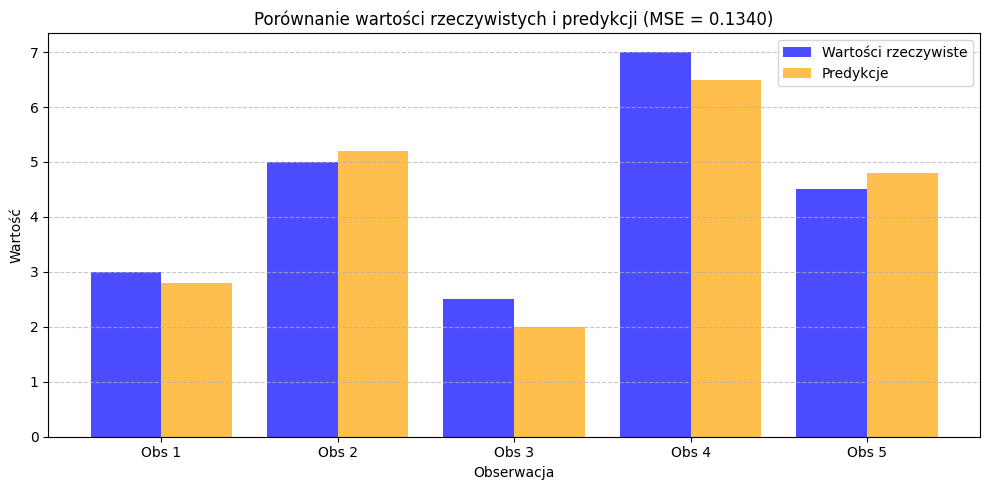

In [ ]:
# Importy potrzebnych bibliotek
import numpy as np
import matplotlib.pyplot as plt
# Przykładowe dane: rzeczywiste wartości i predykcje
y_true = np.array([3.0, 5.0, 2.5, 7.0, 4.5]) # Prawdziwe wartości
y_pred = np.array([2.8, 5.2, 2.0, 6.5, 4.8]) # Predykcje modelu
# Obliczenie MSE ręcznie (bez bibliotek)
# MSE = (1/n) * Σ(y_true - y_pred)²
errors = y_true - y_pred # Różnice między wartościami
squared_errors = errors ** 2 # Podniesienie do kwadratu
mse = np.mean(squared_errors) # Średnia z kwadratów błędów
print("Różnice (błędy):", errors)
print("Kwadraty błędów:", squared_errors)
print(f"MSE = {mse:.4f}")
# Wizualizacja błędów
plt.figure(figsize=(10, 5))
x = np.arange(len(y_true))
plt.bar(x - 0.2, y_true, 0.4, label='Wartości rzeczywiste', color='blue', alpha=0.7)
plt.bar(x + 0.2, y_pred, 0.4, label='Predykcje', color='orange', alpha=0.7)
plt.xlabel('Obserwacja')
plt.ylabel('Wartość')
plt.title(f'Porównanie wartości rzeczywistych i predykcji (MSE = {mse:.4f})')
plt.legend()
plt.xticks(x, [f'Obs {i+1}' for i in x])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

=== Dane bez outliera ===
MSE: 0.1180
MAE: 0.3000

=== Dane z outlierem ===
MSE: 287.3980
MAE: 7.8600

=== Wpływ outliera ===
Wzrost MSE: 2435.6x
Wzrost MAE: 26.2x


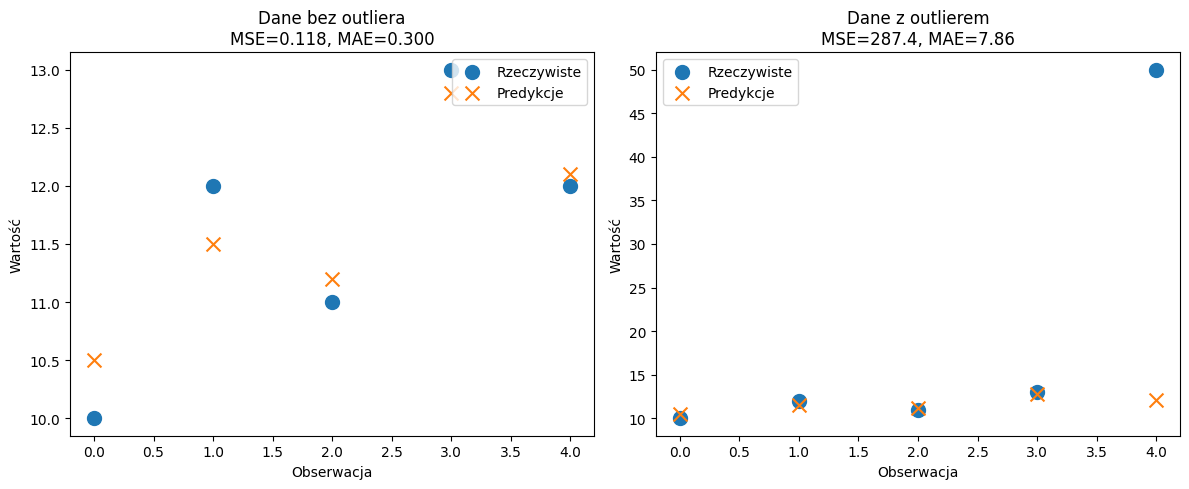

In [ ]:
# Porównanie MSE i MAE na danych z outlierem
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error
# Dane bez outliera
y_true_clean = np.array([10, 12, 11, 13, 12])
y_pred_clean = np.array([10.5, 11.5, 11.2, 12.8, 12.1])
# Dane z outlierem (jedna obserwacja znacznie odbiega)
y_true_outlier = np.array([10, 12, 11, 13, 50]) # 50 to outlier
y_pred_outlier = np.array([10.5, 11.5, 11.2, 12.8, 12.1])
# Obliczenie metryk dla danych czystych
mse_clean = mean_squared_error(y_true_clean, y_pred_clean)
mae_clean = mean_absolute_error(y_true_clean, y_pred_clean)
# Obliczenie metryk dla danych z outlierem
mse_outlier = mean_squared_error(y_true_outlier, y_pred_outlier)
mae_outlier = mean_absolute_error(y_true_outlier, y_pred_outlier)
print("=== Dane bez outliera ===")
print(f"MSE: {mse_clean:.4f}")
print(f"MAE: {mae_clean:.4f}")
print("\n=== Dane z outlierem ===")
print(f"MSE: {mse_outlier:.4f}")
print(f"MAE: {mae_outlier:.4f}")
print("\n=== Wpływ outliera ===")
print(f"Wzrost MSE: {mse_outlier / mse_clean:.1f}x")
print(f"Wzrost MAE: {mae_outlier / mae_clean:.1f}x")
# Wizualizacja
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
# Dane czyste
axes[0].scatter(range(len(y_true_clean)), y_true_clean, label='Rzeczywiste', s=100)
axes[0].scatter(range(len(y_pred_clean)), y_pred_clean, label='Predykcje', s=100,
marker='x')
axes[0].set_title(f'Dane bez outliera\nMSE={mse_clean:.3f}, MAE={mae_clean:.3f}')
axes[0].legend()
axes[0].set_xlabel('Obserwacja')
axes[0].set_ylabel('Wartość')
# Dane z outlierem
axes[1].scatter(range(len(y_true_outlier)), y_true_outlier, label='Rzeczywiste', s=100)
axes[1].scatter(range(len(y_pred_outlier)), y_pred_outlier, label='Predykcje', s=100,
marker='x')
axes[1].set_title(f'Dane z outlierem\nMSE={mse_outlier:.1f}, MAE={mae_outlier:.2f}')
axes[1].legend()
axes[1].set_xlabel('Obserwacja')
axes[1].set_ylabel('Wartość')
plt.tight_layout()
plt.show()

=== Log Loss dla różnych modeli ===
Dobry model: 0.1423
Słaby model: 0.4933
Bardzo zły model: 1.4183

Weryfikacja sklearn (dobry model): 0.1423


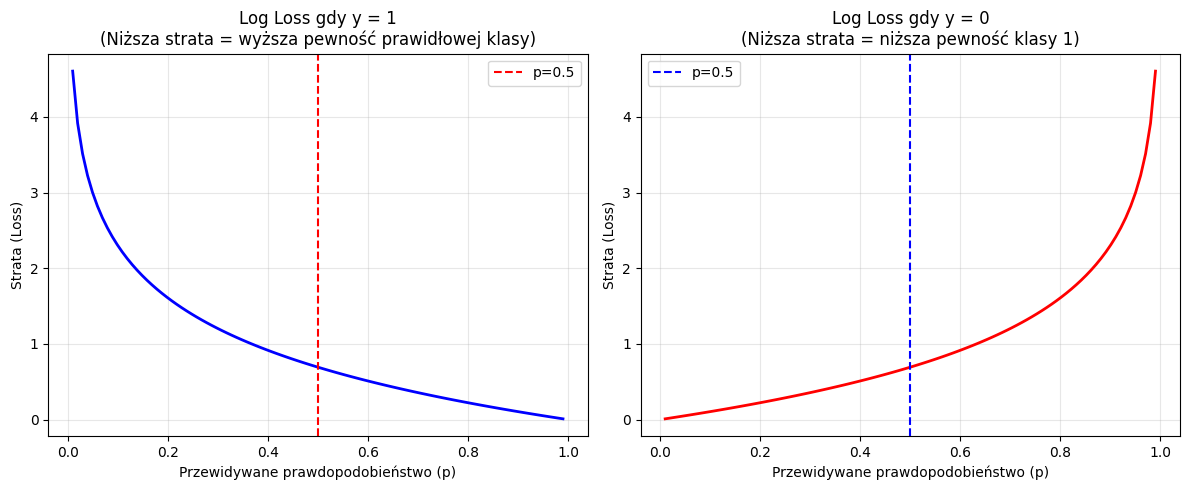

In [ ]:
# Log Loss dla klasyfikacji binarnej
import numpy as np
from sklearn.metrics import log_loss
import matplotlib.pyplot as plt
# Funkcja Log Loss ręcznie
def binary_log_loss(y_true, y_pred_proba, epsilon=1e-15):
  """
  Oblicza Log Loss dla klasyfikacji binarnej.
  Log Loss = -1/n * Σ[y*log(p) + (1-y)*log(1-p)]
  Parametry:
  - y_true: prawdziwe etykiety (0 lub 1)
  - y_pred_proba: przewidywane prawdopodobieństwa klasy 1
  - epsilon: mała wartość zapobiegająca log(0)
  """
  # Ograniczenie prawdopodobieństw do przedziału (epsilon, 1-epsilon)
  y_pred_proba = np.clip(y_pred_proba, epsilon, 1 - epsilon)
  # Obliczenie Log Loss
  loss = -np.mean(
  y_true * np.log(y_pred_proba) +
  (1 - y_true) * np.log(1 - y_pred_proba)
  )
  return loss
# Przykładowe dane - klasyfikacja spam/nie-spam
y_true = np.array([1, 0, 1, 1, 0, 0, 1, 0]) # Rzeczywiste etykiety
# Dobry model - wysokie pewności dla poprawnych klas
y_pred_good = np.array([0.9, 0.1, 0.85, 0.95, 0.2, 0.15, 0.8, 0.1])
# Słaby model - niepewne predykcje
y_pred_bad = np.array([0.6, 0.4, 0.55, 0.7, 0.45, 0.35, 0.65, 0.4])
# Bardzo zły model - odwrócone pewności
y_pred_terrible = np.array([0.2, 0.8, 0.3, 0.25, 0.7, 0.75, 0.35, 0.85])
# Obliczenie Log Loss dla każdego modelu
loss_good = binary_log_loss(y_true, y_pred_good)
loss_bad = binary_log_loss(y_true, y_pred_bad)
loss_terrible = binary_log_loss(y_true, y_pred_terrible)
print("=== Log Loss dla różnych modeli ===")
print(f"Dobry model: {loss_good:.4f}")
print(f"Słaby model: {loss_bad:.4f}")
print(f"Bardzo zły model: {loss_terrible:.4f}")
# Weryfikacja z sklearn
print(f"\nWeryfikacja sklearn (dobry model): {log_loss(y_true, y_pred_good):.4f}")
# Wizualizacja jak Log Loss karze błędne predykcje
p = np.linspace(0.01, 0.99, 100)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
# Gdy y=1 (klasa pozytywna)
axes[0].plot(p, -np.log(p), 'b-', linewidth=2)
axes[0].set_xlabel('Przewidywane prawdopodobieństwo (p)')
axes[0].set_ylabel('Strata (Loss)')
axes[0].set_title('Log Loss gdy y = 1\n(Niższa strata = wyższa pewność prawidłowej klasy)')
axes[0].grid(True, alpha=0.3)
axes[0].axvline(x=0.5, color='r', linestyle='--', label='p=0.5')
axes[0].legend()
# Gdy y=0 (klasa negatywna)
axes[1].plot(p, -np.log(1-p), 'r-', linewidth=2)
axes[1].set_xlabel('Przewidywane prawdopodobieństwo (p)')
axes[1].set_ylabel('Strata (Loss)')
axes[1].set_title('Log Loss gdy y = 0\n(Niższa strata = niższa pewność klasy 1)')
axes[1].grid(True, alpha=0.3)
axes[1].axvline(x=0.5, color='b', linestyle='--', label='p=0.5')
axes[1].legend()
plt.tight_layout()
plt.show()

=== Gradient Descent dla f(x) = x² ===

Iteracja 1: x = 4.000000, f(x) = 16.000000, gradient =10.000000
Iteracja 2: x = 3.200000, f(x) = 10.240000, gradient =8.000000
Iteracja 3: x = 2.560000, f(x) = 6.553600, gradient =6.400000
Iteracja 4: x = 2.048000, f(x) = 4.194304, gradient =5.120000
Iteracja 5: x = 1.638400, f(x) = 2.684355, gradient =4.096000
Iteracja 20: x = 0.057646, f(x) = 0.003323, gradient =0.144115


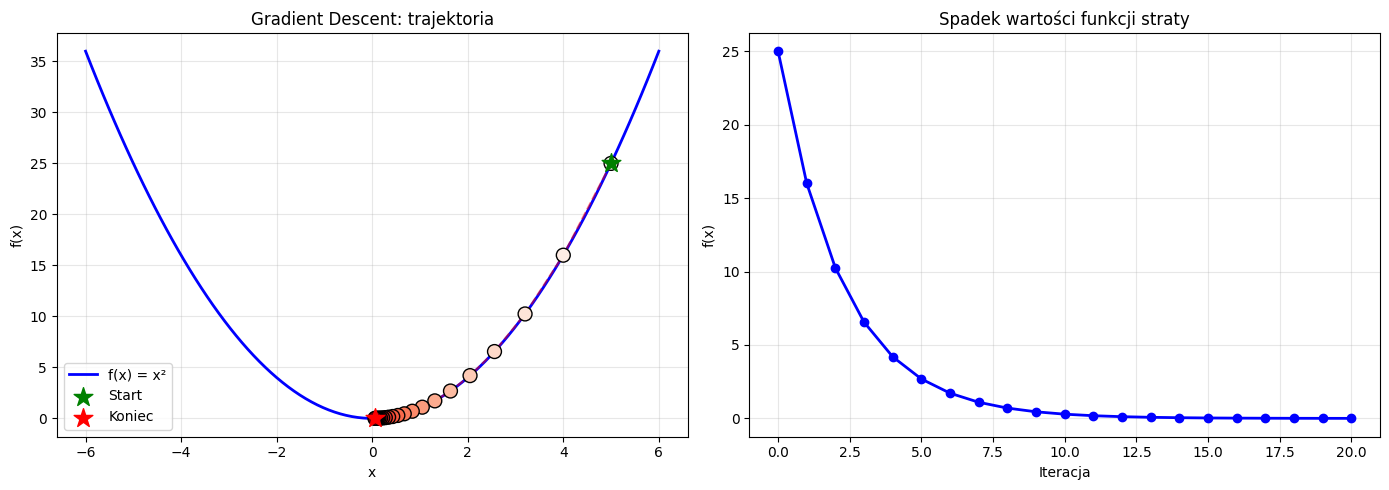


Optymalne x: 0.057646 (powinno być 0)
Minimalna wartość f(x): 0.003323


In [ ]:
# Gradient Descent dla minimalizacji funkcji f(x) = x²
import numpy as np
import matplotlib.pyplot as plt
def function(x):
  """Funkcja do zminimalizowania: f(x) = x²"""
  return x ** 2
def gradient(x):
  """Gradient (pochodna) funkcji: f'(x) = 2x"""
  return 2 * x
def gradient_descent(start_x, learning_rate, num_iterations):
  """
  Algorytm spadku gradientu.
  Parametry:
  - start_x: punkt startowy
  - learning_rate: współczynnik uczenia (η)
  - num_iterations: liczba iteracji
  Zwraca:
  - historia wartości x i f(x)
  """
  x = start_x
  history = {'x': [x], 'f': [function(x)]}
  for i in range(num_iterations):
    # Obliczenie gradientu
    grad = gradient(x)
    # Aktualizacja x: x = x - η * gradient
    x = x - learning_rate * grad
    # Zapisanie historii
    history['x'].append(x)
    history['f'].append(function(x))
    if i < 5 or i == num_iterations - 1:
      print(f"Iteracja {i+1}: x = {x:.6f}, f(x) = {function(x):.6f}, gradient ={grad:.6f}")
  return history
# Uruchomienie gradient descent
print("=== Gradient Descent dla f(x) = x² ===\n")
history = gradient_descent(
start_x=5.0, # Startujemy z x = 5
learning_rate=0.1, # Współczynnik uczenia
num_iterations=20 # Liczba kroków
)
# Wizualizacja
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# Wykres 1: Trajektoria na funkcji
x_range = np.linspace(-6, 6, 100)
axes[0].plot(x_range, function(x_range), 'b-', linewidth=2, label='f(x) = x²')
axes[0].scatter(history['x'], history['f'], c=range(len(history['x'])),
cmap='Reds', s=100, zorder=5, edgecolors='black')
axes[0].plot(history['x'], history['f'], 'r--', alpha=0.5)
axes[0].scatter([history['x'][0]], [history['f'][0]], c='green', s=200,
marker='*', zorder=6, label='Start')
axes[0].scatter([history['x'][-1]], [history['f'][-1]], c='red', s=200,
marker='*', zorder=6, label='Koniec')
axes[0].set_xlabel('x')
axes[0].set_ylabel('f(x)')
axes[0].set_title('Gradient Descent: trajektoria')
axes[0].legend()
axes[0].grid(True, alpha=0.3)
# Wykres 2: Wartość funkcji w czasie
axes[1].plot(history['f'], 'b-o', linewidth=2, markersize=6)
axes[1].set_xlabel('Iteracja')
axes[1].set_ylabel('f(x)')
axes[1].set_title('Spadek wartości funkcji straty')
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print(f"\nOptymalne x: {history['x'][-1]:.6f} (powinno być 0)")
print(f"Minimalna wartość f(x): {history['f'][-1]:.6f}")

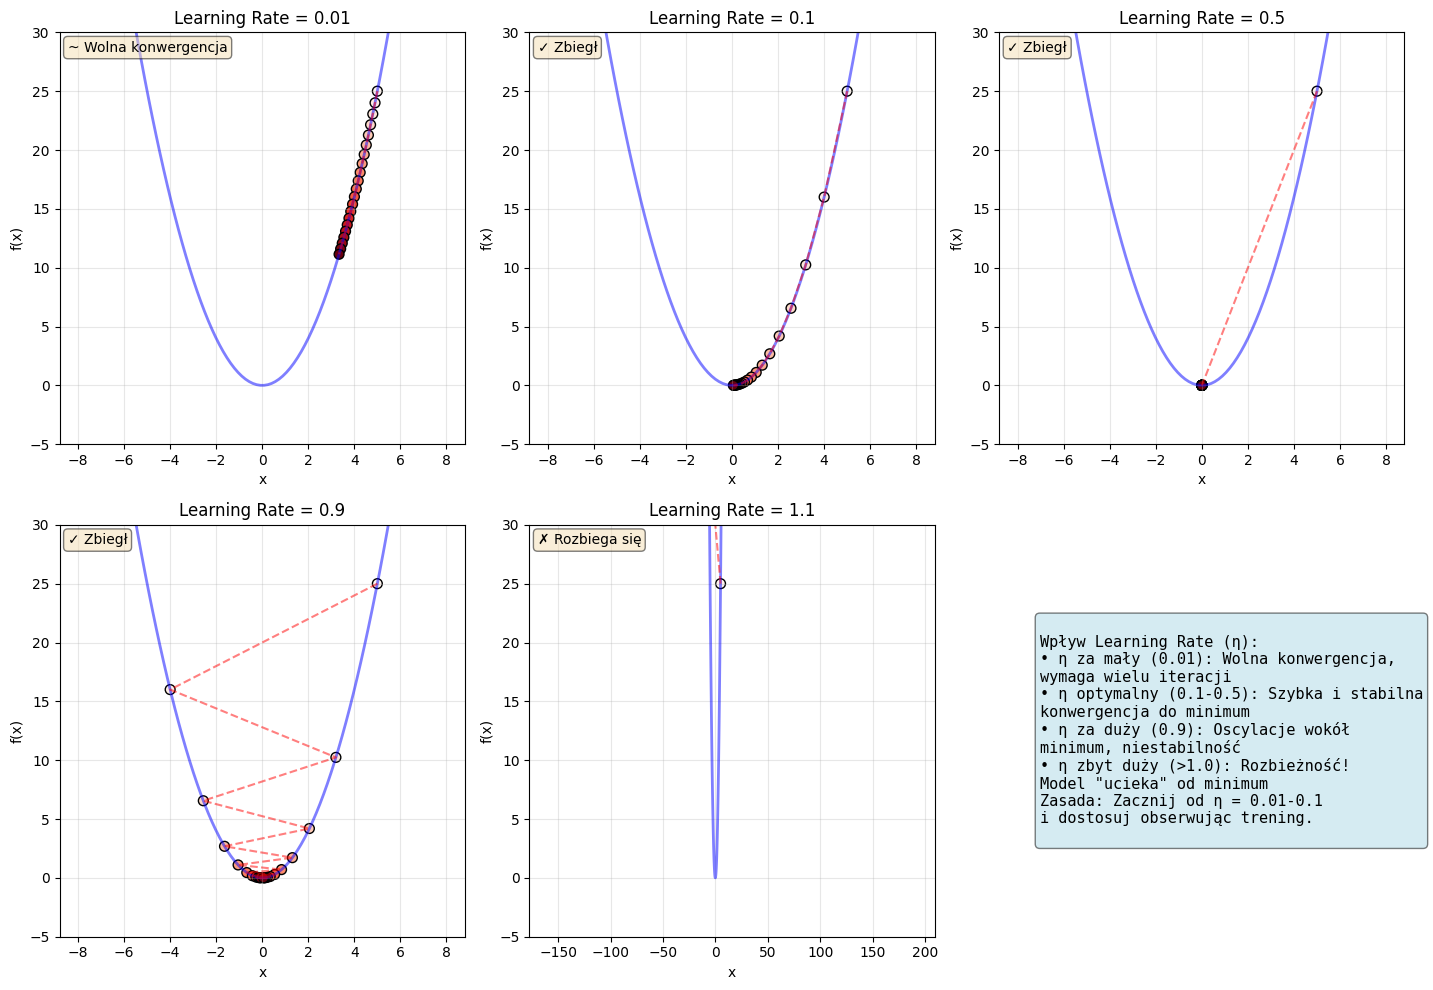

In [ ]:
# Porównanie różnych wartości learning rate
import numpy as np
import matplotlib.pyplot as plt
def function(x):
  return x ** 2
def gradient(x):
  return 2 * x
def run_gd(start_x, learning_rate, num_iterations):
  """Uruchomienie Gradient Descent z określonym learning rate."""
  x = start_x
  history = [x]
  for _ in range(num_iterations):
    x = x - learning_rate * gradient(x)
    history.append(x)
  return history
# Różne wartości learning rate
learning_rates = [0.01, 0.1, 0.5, 0.9, 1.1]
start_x = 5.0
num_iterations = 20
# Wizualizacja
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()
x_range = np.linspace(-8, 8, 100)
for idx, lr in enumerate(learning_rates):
  history = run_gd(start_x, lr, num_iterations)
  ax = axes[idx]
  ax.plot(x_range, function(x_range), 'b-', linewidth=2, alpha=0.5)
  ax.scatter(history, [function(x) for x in history],
  c=range(len(history)), cmap='Reds', s=50, edgecolors='black')
  ax.plot(history, [function(x) for x in history], 'r--', alpha=0.5)
  ax.set_xlabel('x')
  ax.set_ylabel('f(x)')
  ax.set_title(f'Learning Rate = {lr}')
  ax.set_ylim(-5, 30)
  ax.grid(True, alpha=0.3)
  # Status konwergencji
  final_x = history[-1]
  if abs(final_x) < 0.1:
    status = "✓ Zbiegł"
  elif abs(final_x) > 100:
    status = "✗ Rozbiega się"
  else:
    status = "~ Wolna konwergencja"
  ax.text(0.02, 0.98, status, transform=ax.transAxes,
  fontsize=10, verticalalignment='top',
  bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
# Pusty wykres - podsumowanie
ax = axes[5]
ax.axis('off')
summary = """
Wpływ Learning Rate (η):
• η za mały (0.01): Wolna konwergencja,
wymaga wielu iteracji
• η optymalny (0.1-0.5): Szybka i stabilna
konwergencja do minimum
• η za duży (0.9): Oscylacje wokół
minimum, niestabilność
• η zbyt duży (>1.0): Rozbieżność!
Model "ucieka" od minimum
Zasada: Zacznij od η = 0.01-0.1
i dostosuj obserwując trening.
"""
ax.text(0.1, 0.5, summary, fontsize=11, verticalalignment='center',
fontfamily='monospace', bbox=dict(boxstyle='round', facecolor='lightblue',
alpha=0.5))
plt.tight_layout()
plt.show()

Dane: 100 obserwacji
X: zakres [-2.62, 1.85]
y: zakres [-122.37, 102.71]

=== Trening Gradient Descent ===

Iteracja 200: w = 45.7852, b = 1.7477, MSE = 175.6221
Iteracja 400: w = 45.7852, b = 1.7477, MSE = 175.6221
Iteracja 600: w = 45.7852, b = 1.7477, MSE = 175.6221
Iteracja 800: w = 45.7852, b = 1.7477, MSE = 175.6221
Iteracja 1000: w = 45.7852, b = 1.7477, MSE = 175.6221

Wyuczone parametry: w = 45.7852, b = 1.7477
Końcowy MSE: 175.6221


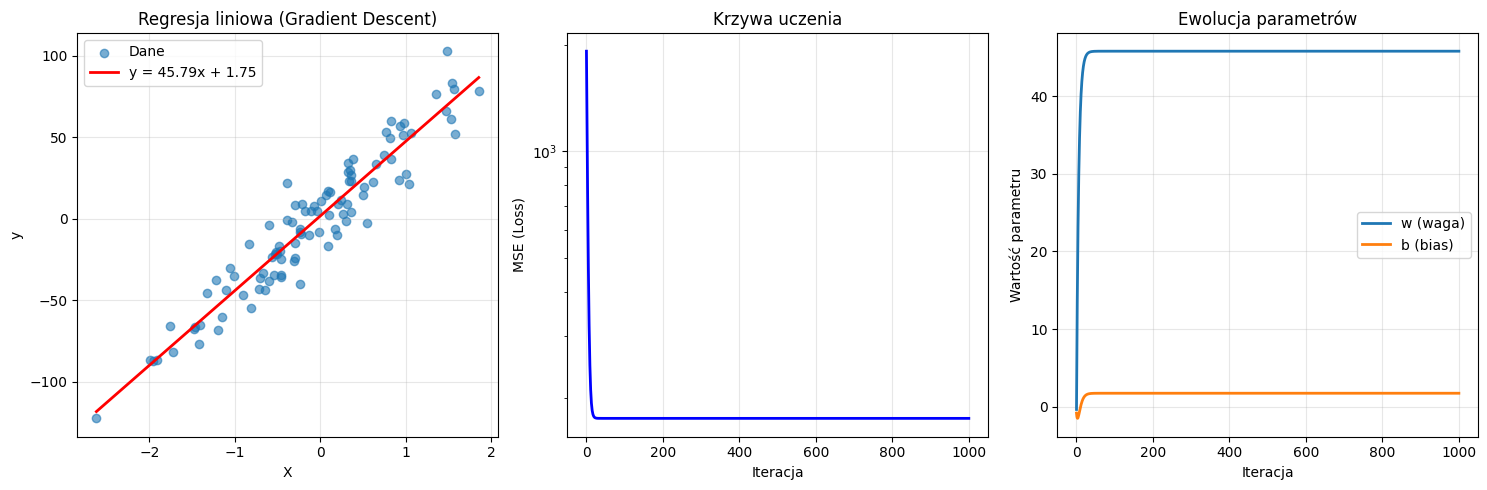


Sklearn LinearRegression: w = 45.7852, b = 1.7477


In [ ]:
# Gradient Descent dla regresji liniowej y = wx + b
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression
# Generowanie danych
np.random.seed(42)
X, y = make_regression(n_samples=100, n_features=1, noise=15)
X = X.flatten()
print(f"Dane: {len(X)} obserwacji")
print(f"X: zakres [{X.min():.2f}, {X.max():.2f}]")
print(f"y: zakres [{y.min():.2f}, {y.max():.2f}]")
def predict(X, w, b):
  """Predykcja: y = wX + b"""
  return w * X + b
def compute_mse(y_true, y_pred):
  """Obliczenie MSE"""
  return np.mean((y_true - y_pred) ** 2)
def compute_gradients(X, y, w, b):
  """
  Obliczenie gradientów dla regresji liniowej.
  MSE = (1/n) * Σ(y - (wx + b))²
  ∂MSE/∂w = (-2/n) * Σ(y - (wx + b)) * x
  ∂MSE/∂b = (-2/n) * Σ(y - (wx + b))
  """
  n = len(y)
  y_pred = predict(X, w, b)
  error = y - y_pred
  dw = (-2/n) * np.sum(error * X)
  db = (-2/n) * np.sum(error)
  return dw, db
def gradient_descent_linear(X, y, learning_rate=0.01, num_iterations=1000):
  """
  Gradient Descent dla regresji liniowej.
  """
  # Inicjalizacja wag (losowa)
  w = np.random.randn()
  b = np.random.randn()
  history = {
  'w': [w], 'b': [b],
  'loss': [compute_mse(y, predict(X, w, b))]
  }
  for i in range(num_iterations):
    # Obliczenie gradientów
    dw, db = compute_gradients(X, y, w, b)
    # Aktualizacja parametrów
    w = w - learning_rate * dw
    b = b - learning_rate * db
    # Zapisanie historii
    loss = compute_mse(y, predict(X, w, b))
    history['w'].append(w)
    history['b'].append(b)
    history['loss'].append(loss)
    if (i + 1) % 200 == 0:
      print(f"Iteracja {i+1}: w = {w:.4f}, b = {b:.4f}, MSE = {loss:.4f}")
  return w, b, history
# Trening
print("\n=== Trening Gradient Descent ===\n")
w_final, b_final, history = gradient_descent_linear(X, y, learning_rate=0.1,
num_iterations=1000)
print(f"\nWyuczone parametry: w = {w_final:.4f}, b = {b_final:.4f}")
print(f"Końcowy MSE: {history['loss'][-1]:.4f}")
# Wizualizacja
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
# 1. Dane i linia regresji
axes[0].scatter(X, y, alpha=0.6, label='Dane')
x_line = np.linspace(X.min(), X.max(), 100)
axes[0].plot(x_line, predict(x_line, w_final, b_final), 'r-',
linewidth=2, label=f'y = {w_final:.2f}x + {b_final:.2f}')
axes[0].set_xlabel('X')
axes[0].set_ylabel('y')
axes[0].set_title('Regresja liniowa (Gradient Descent)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)
# 2. Krzywa uczenia (Loss)
axes[1].plot(history['loss'], 'b-', linewidth=2)
axes[1].set_xlabel('Iteracja')
axes[1].set_ylabel('MSE (Loss)')
axes[1].set_title('Krzywa uczenia')
axes[1].set_yscale('log')
axes[1].grid(True, alpha=0.3)
# 3. Ewolucja parametrów
axes[2].plot(history['w'], label='w (waga)', linewidth=2)
axes[2].plot(history['b'], label='b (bias)', linewidth=2)
axes[2].set_xlabel('Iteracja')
axes[2].set_ylabel('Wartość parametru')
axes[2].set_title('Ewolucja parametrów')
axes[2].legend()
axes[2].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
# Porównanie ze sklearn
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(X.reshape(-1, 1), y)
print(f"\nSklearn LinearRegression: w = {lr.coef_[0]:.4f}, b = {lr.intercept_:.4f}")

=== Porównanie wariantów Gradient Descent ===

Batch GD: w = 16.5188, b = 0.0905, czas = 0.0149s
Mini-batch GD: w = 13.5046, b = 0.3489, czas = 0.1299s
Stochastic GD: w = 16.6286, b = 0.1231, czas = 0.4600s


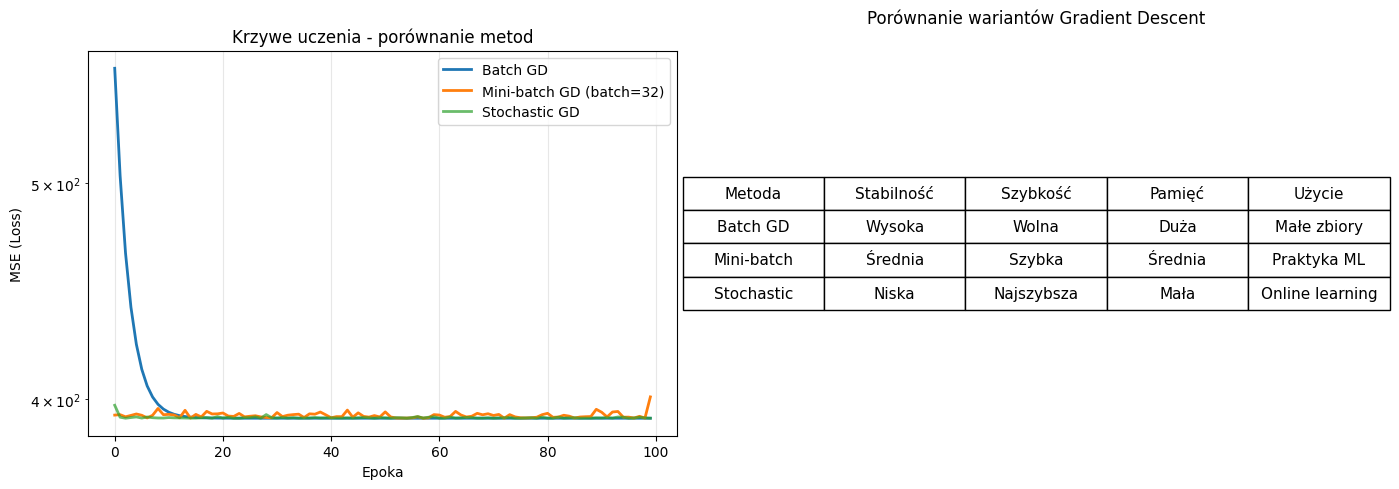

In [ ]:
# Porównanie wariantów Gradient Descent
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression
# Generowanie większego zbioru danych
np.random.seed(42)
X, y = make_regression(n_samples=1000, n_features=1, noise=20)
X = X.flatten()
def predict(X, w, b):
  return w * X + b
def compute_gradients_batch(X, y, w, b):
  """Gradient na całym zbiorze danych (Batch GD)"""
  n = len(y)
  y_pred = predict(X, w, b)
  error = y - y_pred
  dw = (-2/n) * np.sum(error * X)
  db = (-2/n) * np.sum(error)
  return dw, db
def batch_gradient_descent(X, y, lr=0.1, epochs=100):
  """Batch Gradient Descent - używa wszystkich danych w każdej iteracji"""
  w, b = 0.0, 0.0
  losses = []
  for epoch in range(epochs):
    dw, db = compute_gradients_batch(X, y, w, b)
    w -= lr * dw
    b -= lr * db
    loss = np.mean((y - predict(X, w, b))**2)
    losses.append(loss)
  return w, b, losses
def stochastic_gradient_descent(X, y, lr=0.01, epochs=100):
  """Stochastic GD - używa jednej obserwacji na raz"""
  w, b = 0.0, 0.0
  losses = []
  n = len(y)
  for epoch in range(epochs):
    # Losowa kolejność danych
    indices = np.random.permutation(n)
    for i in indices:
      y_pred = predict(X[i], w, b)
      error = y[i] - y_pred
      dw = -2 * error * X[i]
      db = -2 * error
      w -= lr * dw
      b -= lr * db
    loss = np.mean((y - predict(X, w, b))**2)
    losses.append(loss)
  return w, b, losses
def mini_batch_gradient_descent(X, y, lr=0.05, epochs=100, batch_size=32):
  """Mini-batch GD - używa małych porcji danych"""
  w, b = 0.0, 0.0
  losses = []
  n = len(y)
  for epoch in range(epochs):
    # Losowa kolejność danych
    indices = np.random.permutation(n)
    X_shuffled = X[indices]
    y_shuffled = y[indices]
    # Podziel na mini-batche
    for i in range(0, n, batch_size):
      X_batch = X_shuffled[i:i+batch_size]
      y_batch = y_shuffled[i:i+batch_size]
      # Gradient na mini-batchu
      y_pred = predict(X_batch, w, b)
      error = y_batch - y_pred
      dw = (-2/len(X_batch)) * np.sum(error * X_batch)
      db = (-2/len(X_batch)) * np.sum(error)
      w -= lr * dw
      b -= lr * db
    loss = np.mean((y - predict(X, w, b))**2)
    losses.append(loss)
  return w, b, losses
# Uruchomienie wszystkich wariantów
print("=== Porównanie wariantów Gradient Descent ===\n")
import time # `time.perf_counter()` — monotoniczny zegar wysokiej rozdzielczości (Lekcja8)
# Batch GD
start = time.perf_counter()
w_batch, b_batch, losses_batch = batch_gradient_descent(X, y, lr=0.1, epochs=100)
time_batch = time.perf_counter() - start
print(f"Batch GD: w = {w_batch:.4f}, b = {b_batch:.4f}, czas = {time_batch:.4f}s")
# Mini-batch GD
start = time.perf_counter()
w_mini, b_mini, losses_mini = mini_batch_gradient_descent(X, y, lr=0.05, epochs=100,
batch_size=32)
time_mini = time.perf_counter() - start
print(f"Mini-batch GD: w = {w_mini:.4f}, b = {b_mini:.4f}, czas = {time_mini:.4f}s")
# Stochastic GD
start = time.perf_counter()
w_sgd, b_sgd, losses_sgd = stochastic_gradient_descent(X, y, lr=0.001, epochs=100)
time_sgd = time.perf_counter() - start
print(f"Stochastic GD: w = {w_sgd:.4f}, b = {b_sgd:.4f}, czas = {time_sgd:.4f}s")
# Wizualizacja
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# Krzywe uczenia
axes[0].plot(losses_batch, label='Batch GD', linewidth=2)
axes[0].plot(losses_mini, label='Mini-batch GD (batch=32)', linewidth=2)
axes[0].plot(losses_sgd, label='Stochastic GD', linewidth=2, alpha=0.7)
axes[0].set_xlabel('Epoka')
axes[0].set_ylabel('MSE (Loss)')
axes[0].set_title('Krzywe uczenia - porównanie metod')
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[0].set_yscale('log')
# Tabela porównawcza
axes[1].axis('off')
table_data = [
['Metoda', 'Stabilność', 'Szybkość', 'Pamięć', 'Użycie'],
['Batch GD', 'Wysoka', 'Wolna', 'Duża', 'Małe zbiory'],
['Mini-batch', 'Średnia', 'Szybka', 'Średnia', 'Praktyka ML'],
['Stochastic', 'Niska', 'Najszybsza', 'Mała', 'Online learning'],
]
table = axes[1].table(
cellText=table_data[1:],
colLabels=table_data[0],
cellLoc='center',
loc='center',
colWidths=[0.2, 0.2, 0.2, 0.2, 0.2]
)
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1.2, 2)
axes[1].set_title('Porównanie wariantów Gradient Descent', pad=20)

plt.tight_layout()
plt.show()

In [ ]:
# Porównanie optymalizatorów na danych Boston Housing
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_squared_error
# Wczytanie danych
housing = load_diabetes()
X, y = housing.data, housing.target
# Podział na train/test
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.2, random_state=42
)
# Standaryzacja (KRYTYCZNE dla Gradient Descent!)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print(f"Dane treningowe: {X_train_scaled.shape}")
print(f"Dane testowe: {X_test_scaled.shape}")
# Różne strategie learning rate (harmonogramy) w SGDRegressor
# Dostępne opcje: 'constant', 'optimal', 'invscaling', 'adaptive'
lr_schedules = ['constant', 'invscaling', 'adaptive']
learning_rates = [0.01, 0.001, 0.0001]
results = []
for schedule in lr_schedules:
  for lr in learning_rates:
    # SGDRegressor zawsze używa Stochastic Gradient Descent;
    # parametr `learning_rate` wybiera tylko harmonogram zmian η w czasie treningu
    model = SGDRegressor(
    learning_rate=schedule,
    eta0=lr,
    max_iter=1000,
    tol=1e-6,
    random_state=42
    )
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    mse = mean_squared_error(y_test, y_pred)
    results.append({
    'schedule': schedule,
    'lr': lr,
    'mse': mse,
    'iterations': model.n_iter_
    })
    print(f"{schedule:12} eta0={lr:.4f}: MSE = {mse:.4f}, iteracje = {model.n_iter_}")
# Najlepszy wynik
best = min(results, key=lambda x: x['mse'])
print(f"\n=== Najlepszy wynik ===")
print(f"Harmonogram: {best['schedule']}, eta0: {best['lr']}")
print(f"MSE: {best['mse']:.4f}")

Dane treningowe: (353, 10)
Dane testowe: (89, 10)
constant     eta0=0.0100: MSE = 3026.1508, iteracje = 11
constant     eta0=0.0010: MSE = 2883.4552, iteracje = 30
constant     eta0=0.0001: MSE = 2885.3097, iteracje = 340
invscaling   eta0=0.0100: MSE = 2883.7200, iteracje = 17
invscaling   eta0=0.0010: MSE = 2885.4613, iteracje = 1000


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_stochastic_gradient.py:1608: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_stochastic_gradient.py:1608: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_stochastic_gradient.py:1608: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


invscaling   eta0=0.0001: MSE = 3522.7942, iteracje = 1000
adaptive     eta0=0.0100: MSE = 2887.6677, iteracje = 1000
adaptive     eta0=0.0010: MSE = 2885.7244, iteracje = 1000
adaptive     eta0=0.0001: MSE = 2885.4180, iteracje = 1000

=== Najlepszy wynik ===
Harmonogram: constant, eta0: 0.001
MSE: 2883.4552


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_stochastic_gradient.py:1608: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_stochastic_gradient.py:1608: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


=== Podział danych ===
Zbiór treningowy: 12384 (60%)
Zbiór walidacyjny: 4128 (20%)
Zbiór testowy: 4128 (20%)
Razem: 20640 (100%)
LR = 0.0001: Train MSE = 0.5190, Val MSE = 0.5339
LR = 0.001: Train MSE = 26117920151292.2266, Val MSE = 200229354866660.2812
LR = 0.01: Train MSE = 226938143153373172465664.0000, Val MSE = 1751180787040081827332096.0000
LR = 0.1: Train MSE = 1079393203717809373184.0000, Val MSE = 5078769236943279489024.0000

=== Najlepszy model (wg walidacji) ===
Learning Rate: 0.0001
Test MSE (finalna ocena): 0.5584


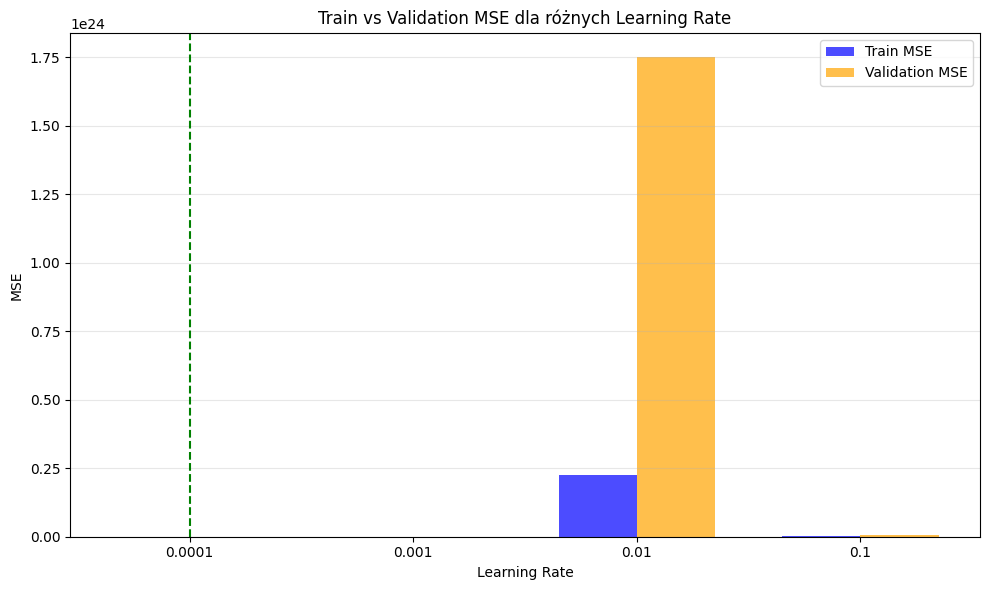

In [ ]:
# Prawidłowy podział danych
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_squared_error
# Wczytanie danych
housing = fetch_california_housing()
X, y = housing.data, housing.target
# KROK 1: Oddzielenie zbioru testowego (20%)
X_temp, X_test, y_temp, y_test = train_test_split(
X, y, test_size=0.2, random_state=42
)
# KROK 2: Podział na train i validation (z pozostałych 80%)
X_train, X_val, y_train, y_val = train_test_split(
X_temp, y_temp, test_size=0.25, random_state=42 # 0.25 * 0.8 = 0.2
)
print("=== Podział danych ===")
print(f"Zbiór treningowy: {len(X_train)} ({len(X_train)/len(X)*100:.0f}%)")
print(f"Zbiór walidacyjny: {len(X_val)} ({len(X_val)/len(X)*100:.0f}%)")
print(f"Zbiór testowy: {len(X_test)} ({len(X_test)/len(X)*100:.0f}%)")
print(f"Razem: {len(X)} (100%)")
# Standaryzacja - FIT tylko na train!
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val) # Transform (nie fit!)
X_test_scaled = scaler.transform(X_test) # Transform (nie fit!)
# Trening z różnymi hiperparametrami
learning_rates = [0.0001, 0.001, 0.01, 0.1]
results = []
for lr in learning_rates:
  model = SGDRegressor(
  learning_rate='constant',
  eta0=lr,
  max_iter=2000,
  random_state=42
  )
  model.fit(X_train_scaled, y_train)
  # Ewaluacja na train i validation
  train_mse = mean_squared_error(y_train, model.predict(X_train_scaled))
  val_mse = mean_squared_error(y_val, model.predict(X_val_scaled))
  results.append({
  'lr': lr,
  'train_mse': train_mse,
  'val_mse': val_mse
  })
  print(f"LR = {lr}: Train MSE = {train_mse:.4f}, Val MSE = {val_mse:.4f}")
# Wybór najlepszego modelu na podstawie validation
best = min(results, key=lambda x: x['val_mse'])
print(f"\n=== Najlepszy model (wg walidacji) ===")
print(f"Learning Rate: {best['lr']}")
# DOPIERO TERAZ ewaluacja na teście
final_model = SGDRegressor(
learning_rate='constant',
eta0=best['lr'],
max_iter=2000,
random_state=42
)
final_model.fit(X_train_scaled, y_train)
test_mse = mean_squared_error(y_test, final_model.predict(X_test_scaled))
print(f"Test MSE (finalna ocena): {test_mse:.4f}")
# Wizualizacja
fig, ax = plt.subplots(figsize=(10, 6))
x = range(len(learning_rates))
width = 0.35
train_mses = [r['train_mse'] for r in results]
val_mses = [r['val_mse'] for r in results]
bars1 = ax.bar([i - width/2 for i in x], train_mses, width, label='Train MSE',
color='blue', alpha=0.7)
bars2 = ax.bar([i + width/2 for i in x], val_mses, width, label='Validation MSE',
color='orange', alpha=0.7)
ax.set_xlabel('Learning Rate')
ax.set_ylabel('MSE')
ax.set_title('Train vs Validation MSE dla różnych Learning Rate')
ax.set_xticks(x)
ax.set_xticklabels([str(lr) for lr in learning_rates])
ax.legend()
ax.grid(axis='y', alpha=0.3)
# Zaznaczenie najlepszego
best_idx = learning_rates.index(best['lr'])
ax.axvline(x=best_idx, color='green', linestyle='--', label='Najlepszy')
plt.tight_layout()
plt.show()

=== 5-Fold Cross-Validation ===
MSE dla każdego folda: [2.70538125e+21 1.04079351e+20 2.19468650e+21 1.37162861e+09
 3.00303888e+21]
Średnie MSE: 1601437196378294452224.0000
Odchylenie std: 1291650579459787456512.0000
95% przedział ufności: 1601437196378294452224.0000 ± 2531635135741183393792.0000
K=3: MSE = 2279936233359952576512.0000 ± 1790245730410239361024.0000
K=5: MSE = 1601437196378294452224.0000 ± 1291650579459787456512.0000
K=10: MSE = 15004083799688485011456.0000 ± 38404734399552541425664.0000
K=20: MSE = 20692686639751598440448.0000 ± 57027237906296812339200.0000


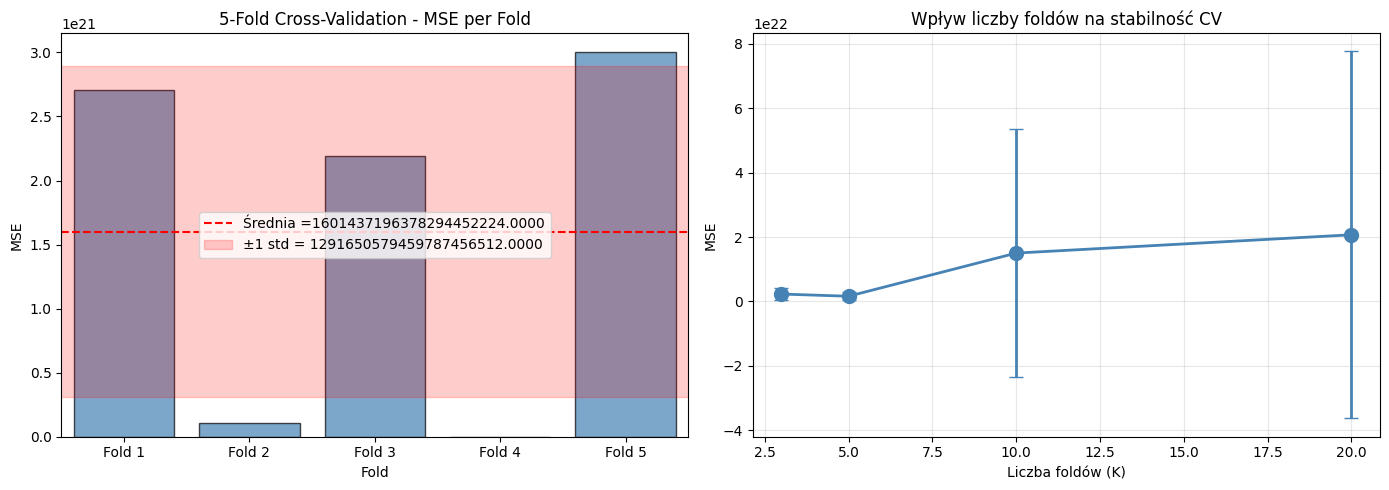

In [ ]:
# K-Fold Cross-Validation
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDRegressor
from sklearn.pipeline import Pipeline
# Wczytanie danych
housing = fetch_california_housing()
X, y = housing.data, housing.target
# Pipeline: standaryzacja + model
pipeline = Pipeline([
('scaler', StandardScaler()),
('model', SGDRegressor(learning_rate='constant', eta0=0.01, max_iter=1000,
random_state=42))
])
# 5-Fold Cross-Validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)
# Obliczenie scores (domyślnie R², używamy neg_mean_squared_error)
cv_scores = cross_val_score(
    pipeline, X, y,
cv=kf,
scoring='neg_mean_squared_error'
)
# Konwersja na MSE (wyniki są negatywne)
mse_scores = -cv_scores
print("=== 5-Fold Cross-Validation ===")
print(f"MSE dla każdego folda: {mse_scores}")
print(f"Średnie MSE: {mse_scores.mean():.4f}")
print(f"Odchylenie std: {mse_scores.std():.4f}")
print(f"95% przedział ufności: {mse_scores.mean():.4f} ± {1.96 * mse_scores.std():.4f}")
# Porównanie różnych wartości K
k_values = [3, 5, 10, 20]
cv_results = []
for k in k_values:
  kf = KFold(n_splits=k, shuffle=True, random_state=42)
  scores = cross_val_score(pipeline, X, y, cv=kf, scoring='neg_mean_squared_error')
  mse = -scores
  cv_results.append({
  'k': k,
  'mean': mse.mean(),
  'std': mse.std()
  })
  print(f"K={k}: MSE = {mse.mean():.4f} ± {mse.std():.4f}")
# Wizualizacja
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# 1. Wyniki dla 5-fold
axes[0].bar(range(5), mse_scores, color='steelblue', alpha=0.7, edgecolor='black')
axes[0].axhline(y=mse_scores.mean(), color='red', linestyle='--', label=f'Średnia ={mse_scores.mean():.4f}')
axes[0].fill_between(
range(-1, 6),
mse_scores.mean() - mse_scores.std(),
mse_scores.mean() + mse_scores.std(),
color='red', alpha=0.2, label=f'±1 std = {mse_scores.std():.4f}'
)
axes[0].set_xlabel('Fold')
axes[0].set_ylabel('MSE')
axes[0].set_title('5-Fold Cross-Validation - MSE per Fold')
axes[0].set_xticks(range(5))
axes[0].set_xticklabels([f'Fold {i+1}' for i in range(5)])
axes[0].legend()
axes[0].set_xlim(-0.5, 4.5)
# 2. Porównanie różnych K
means = [r['mean'] for r in cv_results]
stds = [r['std'] for r in cv_results]
axes[1].errorbar(k_values, means, yerr=stds, fmt='o-', capsize=5,
linewidth=2, markersize=10, color='steelblue')
axes[1].set_xlabel('Liczba foldów (K)')
axes[1].set_ylabel('MSE')
axes[1].set_title('Wpływ liczby foldów na stabilność CV')
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

=== Learning Curves Analysis ===
Rozmiary treningowe: [ 1651  3302  4953  6604  8256  9907 11558 13209 14860 16512]

Train MSE (final): 34620850425395899531264.0000
Val MSE (final): 15619760944245957984256.0000
Gap: -19001089481149939449856.0000

Diagnoza: ✓ Model dobrze uogólnia (mały gap)


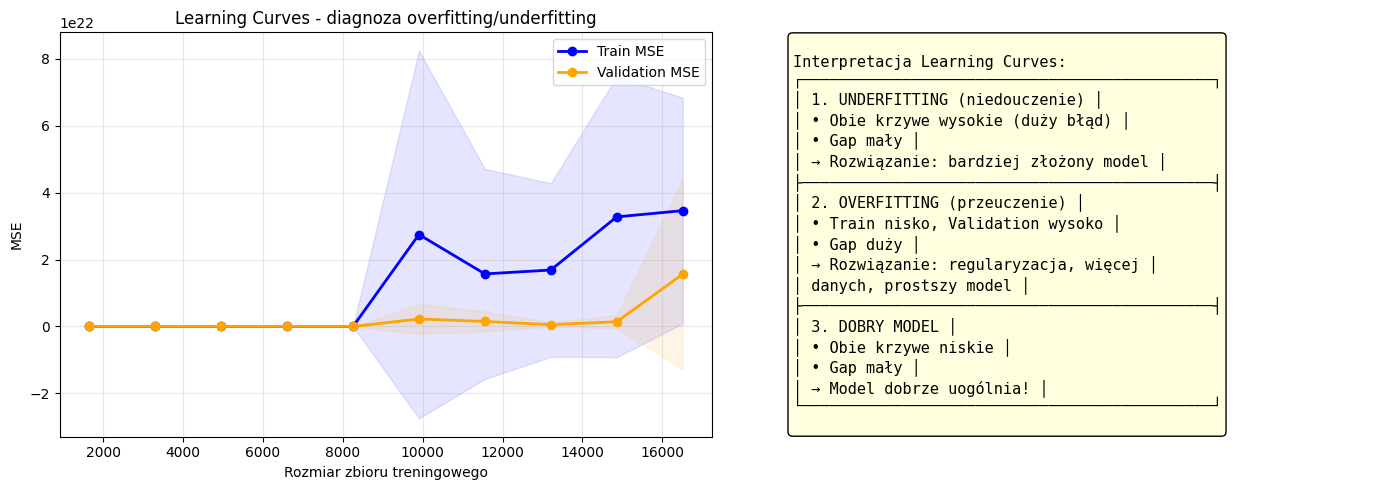

In [ ]:
# Wykrywanie overfitting przez learning curves
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import learning_curve, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDRegressor
from sklearn.pipeline import Pipeline
# Wczytanie danych
housing = fetch_california_housing()
X, y = housing.data, housing.target
# Pipeline
pipeline = Pipeline([
('scaler', StandardScaler()),
('model', SGDRegressor(learning_rate='constant', eta0=0.01, max_iter=1000,
random_state=42))
])
# Learning curves
train_sizes, train_scores, val_scores = learning_curve(
pipeline, X, y,
train_sizes=np.linspace(0.1, 1.0, 10),cv=5,
scoring='neg_mean_squared_error',
n_jobs=-1
)
# Konwersja na MSE i obliczenie średnich
train_mse = -train_scores.mean(axis=1)
val_mse = -val_scores.mean(axis=1)
train_std = train_scores.std(axis=1)
val_std = val_scores.std(axis=1)
print("=== Learning Curves Analysis ===")
print(f"Rozmiary treningowe: {train_sizes}")
print(f"\nTrain MSE (final): {train_mse[-1]:.4f}")
print(f"Val MSE (final): {val_mse[-1]:.4f}")
print(f"Gap: {val_mse[-1] - train_mse[-1]:.4f}")
# Interpretacja
gap = val_mse[-1] - train_mse[-1]
if gap < 0.1:
  diagnosis = "✓ Model dobrze uogólnia (mały gap)"
elif gap < 0.5:
  diagnosis = "⚠ Lekki overfitting (średni gap)"
else:
  diagnosis = "✗ Silny overfitting (duży gap)"
print(f"\nDiagnoza: {diagnosis}")
# Wizualizacja
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# 1. Learning curves
axes[0].fill_between(train_sizes, train_mse - train_std, train_mse + train_std, alpha=0.1,
color='blue')
axes[0].fill_between(train_sizes, val_mse - val_std, val_mse + val_std, alpha=0.1,
color='orange')
axes[0].plot(train_sizes, train_mse, 'o-', label='Train MSE', color='blue', linewidth=2)
axes[0].plot(train_sizes, val_mse, 'o-', label='Validation MSE', color='orange',
linewidth=2)
axes[0].set_xlabel('Rozmiar zbioru treningowego')
axes[0].set_ylabel('MSE')
axes[0].set_title('Learning Curves - diagnoza overfitting/underfitting')
axes[0].legend(loc='upper right')
axes[0].grid(True, alpha=0.3)
# 2. Schemat interpretacji
axes[1].axis('off')
interpretations = """
Interpretacja Learning Curves:
┌─────────────────────────────────────────────┐
│ 1. UNDERFITTING (niedouczenie) │
│ • Obie krzywe wysokie (duży błąd) │
│ • Gap mały │
│ → Rozwiązanie: bardziej złożony model │
├─────────────────────────────────────────────┤
│ 2. OVERFITTING (przeuczenie) │
│ • Train nisko, Validation wysoko │
│ • Gap duży │
│ → Rozwiązanie: regularyzacja, więcej │
│ danych, prostszy model │
├─────────────────────────────────────────────┤
│ 3. DOBRY MODEL │
│ • Obie krzywe niskie │
│ • Gap mały │
│ → Model dobrze uogólnia! │
└─────────────────────────────────────────────┘
"""
axes[1].text(0.1, 0.5, interpretations, fontsize=11, verticalalignment='center',
fontfamily='monospace', bbox=dict(boxstyle='round', facecolor='lightyellow'))
plt.tight_layout()
plt.show()

In [ ]:
#zadanie 1
import numpy as np
import matplotlib.pyplot as plt
# Przykładowe dane: rzeczywiste wartości i predykcje
y_true = np.array([10,20,30,40,50]) # Prawdziwe wartości
y_pred = np.array([12,18,33,37,52]) # Predykcje modelu
# Obliczenie MSE ręcznie (bez bibliotek)
# MSE = (1/n) * Σ(y_true - y_pred)²
errors = y_true - y_pred # Różnice między wartościami
squared_errors = errors ** 2 # Podniesienie do kwadratu
mse = np.mean(squared_errors) # Średnia z kwadratów błędów
print("Różnice (błędy):", errors)
print("Kwadraty błędów:", squared_errors)
print(f"MSE = {mse:.4f}")
# MAE = (1/n) * Σ|y_true - y_pred|
errors = y_true - y_pred # Różnice między wartościami
abs_errors = abs(errors) # Podniesienie do kwadratu
mae = np.mean(abs_errors) # Średnia z kwadratów błędów
print("Różnice (błędy):", errors)
print("Abs błędów:", abs_errors)
print(f"MAE = {mae:.4f}")

Różnice (błędy): [-2  2 -3  3 -2]
Kwadraty błędów: [4 4 9 9 4]
MSE = 6.0000
Różnice (błędy): [-2  2 -3  3 -2]
Abs błędów: [2 2 3 3 2]
MAE = 2.4000


In [ ]:
#zadanie 2
np.random.seed(42)
values = np.random.normal(loc=50, scale=10, size=20)
#MSE
errors = values - np.mean(values) # Różnice między wartościami
squared_errors = errors ** 2 # Podniesienie do kwadratu
mse = np.mean(squared_errors) # Średnia z kwadratów błędów
print(f"MSE = {mse:.4f}")

# MAE = (1/n) * Σ|y_true - y_pred|
errors = values - np.mean(values) # Różnice między wartościami
abs_errors = abs(errors) # Podniesienie do kwadratu
mae = np.mean(abs_errors) # Średnia z kwadratów błędów
print(f"MAE = {mae:.4f}")

values = np.append(values, 200)

#MSE
errors = values - np.mean(values) # Różnice między wartościami
squared_errors = errors ** 2 # Podniesienie do kwadratu
mse_o = np.mean(squared_errors) # Średnia z kwadratów błędów
print(f"MSE z outlinerem = {mse_o:.4f}")

# MAE = (1/n) * Σ|y_true - y_pred|
errors = values - np.mean(values) # Różnice między wartościami
abs_errors = abs(errors) # Podniesienie do kwadratu
mae_o = np.mean(abs_errors) # Średnia z kwadratów błędów
print(f"MAE z outlinerem = {mae_o:.4f}")

print(f"Różnica w MSE {abs(mse-mse_o):.4f} jest duża, bardzo czuły na outlinery")
print(f"Różnica w MAE {abs(mae-mae_o):.4f} jest mniejsza, mniej czuły na outlinery")

MSE = 87.5572
MAE = 7.5163
MSE z outlinerem = 1127.2350
MAE z outlinerem = 15.9635
Różnica w MSE 1039.6778 jest duża, bardzo czuły na outlinery
Różnica w MAE 8.4472 jest mniejsza, mniej czuły na outlinery


=== Gradient Descent dla f(x) = x^3 ===

Iteracja 1: x = 7.000000, f(x) = 343.000000, gradient =30.000000
Iteracja 2: x = 4.900000, f(x) = 117.649000, gradient =21.000000
Iteracja 3: x = 3.430000, f(x) = 40.353607, gradient =14.700000
Iteracja 4: x = 2.401000, f(x) = 13.841287, gradient =10.290000
Iteracja 5: x = 1.680700, f(x) = 4.747562, gradient =7.203000
Iteracja 50: x = 0.000000, f(x) = 0.000000, gradient =0.000001


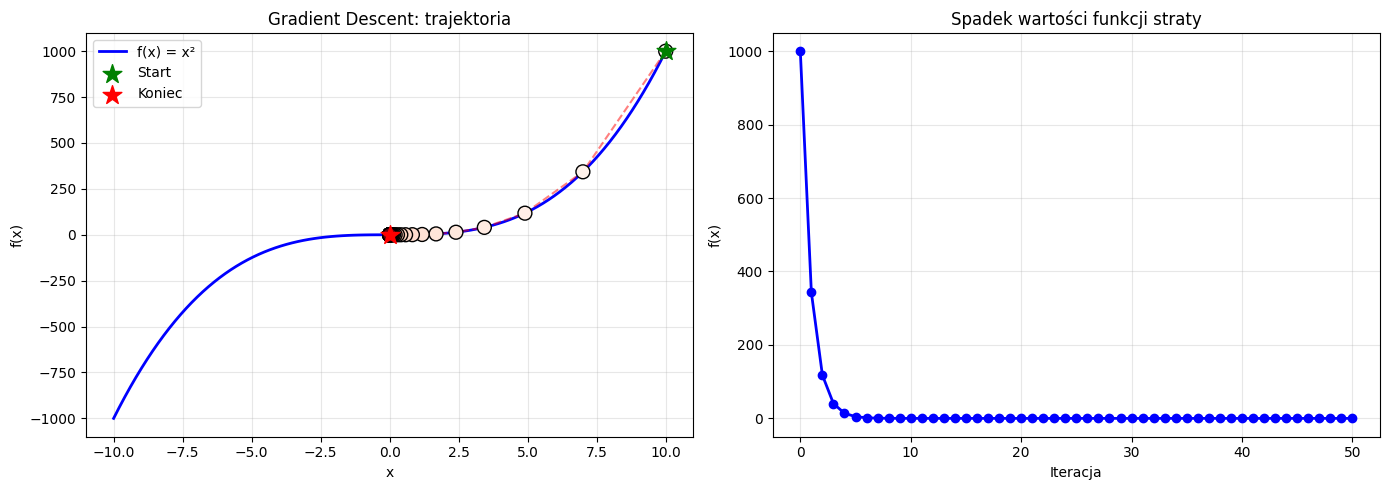


Optymalne x: 0.000000 (powinno być 0)
Minimalna wartość f(x): 0.000000


In [ ]:
# Zadanie 4 Gradient Descent dla minimalizacji funkcji f(x) = x^3
import numpy as np
import matplotlib.pyplot as plt
def function(x):
  return x ** 3
def gradient(x):
  return 3 * x
def gradient_descent(start_x, learning_rate, num_iterations):
  x = start_x
  history = {'x': [x], 'f': [function(x)]}
  for i in range(num_iterations):
    # Obliczenie gradientu
    grad = gradient(x)
    # Aktualizacja x: x = x - η * gradient
    x = x - learning_rate * grad
    # Zapisanie historii
    history['x'].append(x)
    history['f'].append(function(x))
    if i < 5 or i == num_iterations - 1:
      print(f"Iteracja {i+1}: x = {x:.6f}, f(x) = {function(x):.6f}, gradient ={grad:.6f}")
  return history
# Uruchomienie gradient descent
print("=== Gradient Descent dla f(x) = x^3 ===\n")
history = gradient_descent(
start_x=10.0, # Startujemy z x = 5
learning_rate=0.1, # Współczynnik uczenia
num_iterations=50 # Liczba kroków
)
# Wizualizacja
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# Wykres 1: Trajektoria na funkcji
x_range = np.linspace(-10, 10, 100)
axes[0].plot(x_range, function(x_range), 'b-', linewidth=2, label='f(x) = x²')
axes[0].scatter(history['x'], history['f'], c=range(len(history['x'])),
cmap='Reds', s=100, zorder=5, edgecolors='black')
axes[0].plot(history['x'], history['f'], 'r--', alpha=0.5)
axes[0].scatter([history['x'][0]], [history['f'][0]], c='green', s=200,
marker='*', zorder=6, label='Start')
axes[0].scatter([history['x'][-1]], [history['f'][-1]], c='red', s=200,
marker='*', zorder=6, label='Koniec')
axes[0].set_xlabel('x')
axes[0].set_ylabel('f(x)')
axes[0].set_title('Gradient Descent: trajektoria')
axes[0].legend()
axes[0].grid(True, alpha=0.3)
# Wykres 2: Wartość funkcji w czasie
axes[1].plot(history['f'], 'b-o', linewidth=2, markersize=6)
axes[1].set_xlabel('Iteracja')
axes[1].set_ylabel('f(x)')
axes[1].set_title('Spadek wartości funkcji straty')
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print(f"\nOptymalne x: {history['x'][-1]:.6f} (powinno być 0)")
print(f"Minimalna wartość f(x): {history['f'][-1]:.6f}")

=== Gradient Descent dla f(x) = x^3 ===


Dla lr 0.001:
Końcowe x: 4.708540
Końcowe f(x): 22.170347

Dla lr 0.01:
Końcowe x: 2.727422
Końcowe f(x): 7.438829

Dla lr 0.1:
Końcowe x: 0.006190
Końcowe f(x): 0.000038

Dla lr 0.5:
Końcowe x: 0.000000
Końcowe f(x): 0.000000

Dla lr 1.0:
Końcowe x: 5.000000
Końcowe f(x): 25.000000

Dla lr 1.5:
Końcowe x: 5368709120.000000
Końcowe f(x): 28823037615171174400.000000


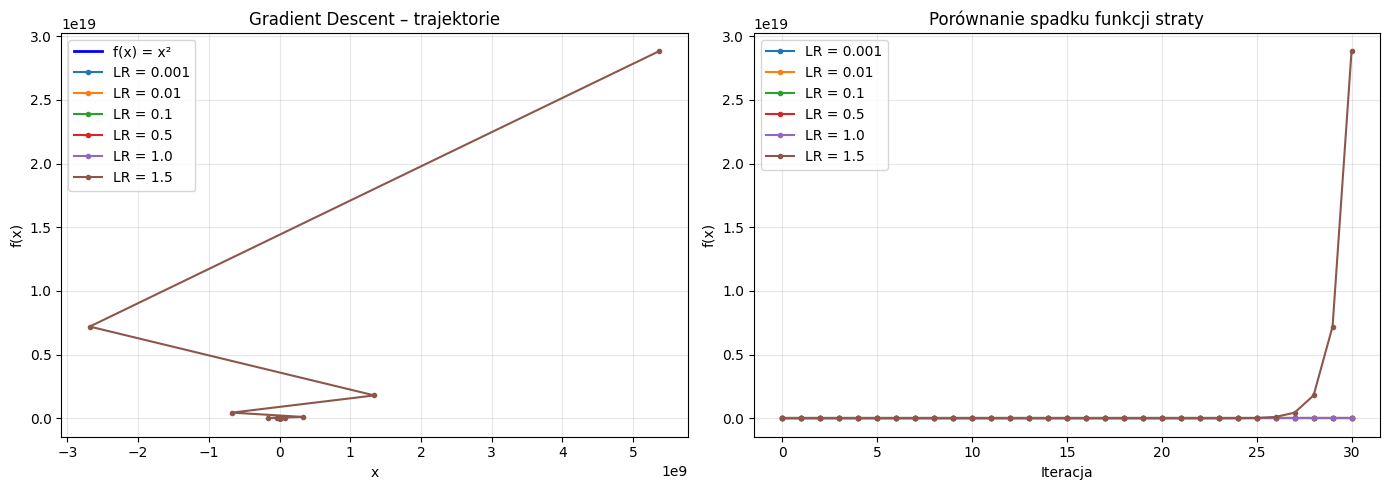

In [5]:
# Zadanie 5  Porównanie Learning Rates
import numpy as np
import matplotlib.pyplot as plt
def function(x):
  return x ** 2
def gradient(x):
  return 2 * x
def gradient_descent(start_x, learning_rate, num_iterations):
  x = start_x
  history = {'x': [x], 'f': [function(x)]}
  for i in range(num_iterations):
    # Obliczenie gradientu
    grad = gradient(x)
    # Aktualizacja x: x = x - η * gradient
    x = x - learning_rate * grad
    # Zapisanie historii
    history['x'].append(x)
    history['f'].append(function(x))
  return history
# Uruchomienie gradient descent
print("=== Gradient Descent dla f(x) = x^3 ===\n")
learning_rates = [0.001, 0.01, 0.1, 0.5, 1.0, 1.5]
results = {}
for lr in learning_rates:
  history = gradient_descent(
  start_x=5.0, # Startujemy z x = 5
  learning_rate=lr, # Współczynnik uczenia
  num_iterations=30 # Liczba kroków
  )
  results[lr] = history
  print(f"\nDla lr {lr}:")
  print(f"Końcowe x: {history['x'][-1]:.6f}")
  print(f"Końcowe f(x): {history['f'][-1]:.6f}")
# Wizualizacja
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# Wykres 1: Trajektoria na funkcji
x_range = np.linspace(-10, 10, 100)
axes[0].plot(x_range, function(x_range), 'b-', linewidth=2, label='f(x) = x²')
for lr, history in results.items():
  axes[0].plot(
    history['x'],
    history['f'],
    marker='o',
    markersize=3,
    label=f'LR = {lr}'
  )
axes[0].set_xlabel('x')
axes[0].set_ylabel('f(x)')
axes[0].set_title('Gradient Descent – trajektorie')
axes[0].legend()
axes[0].grid(True, alpha=0.3)
# Wykres 2: Wartość funkcji w czasie
for lr, history in results.items():
  axes[1].plot(
    history['f'],
    marker='o',
    markersize=3,
    label=f'LR = {lr}'
  )

axes[1].set_xlabel('Iteracja')
axes[1].set_ylabel('f(x)')
axes[1].set_title('Porównanie spadku funkcji straty')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
# bez lr 1.5 ładniej wygląda :) Zaczyna on bardzo szybko eksplodować

In [ ]:
#zadanie 6
import numpy as np
import pandas as pd

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

iris = load_iris()

x=iris.data
y=iris.target

class_names = iris.target_names

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Liczba obserwacji:")
print("Cały dataset:", len(y))
print("Train:", len(y_train))
print("Test:", len(y_test))

train_counts = np.bincount(y_train)
test_counts = np.bincount(y_test)
total_counts =np.bincount(y)

distribution = pd.DataFrame({
    'Klasa' : class_names,
    'Caly dataset' : total_counts,
    'Train' : train_counts,
    'Test' : test_counts,
    'Train (%)' : train_counts / len(y_train) * 100,
    'Test (%)' : test_counts / len(y_test) * 100
})

print("Rozklad klas:")
print(distribution.to_string(index=False))

Liczba obserwacji:
Cały dataset: 150
Train: 120
Test: 30
Rozklad klas:
     Klasa  Caly dataset  Train  Test  Train (%)  Test (%)
    setosa            50     40    10  33.333333 33.333333
versicolor            50     40    10  33.333333 33.333333
 virginica            50     40    10  33.333333 33.333333


In [ ]:
#zadanie 7
import numpy as np
import pandas as pd

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

housing = fetch_california_housing()

x = housing.data[:,:3]
y= housing.target

feature_names = housing.feature_names[:3]

print("Wybrane cechy:", feature_names)
print("Rozmiar danych:", x.shape)

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
)

print("Liczba obserwacji:")
print("Train:", len(x_train))
print("Test:", len(x_test))

before= pd.DataFrame({
    'Cecha' : feature_names,
    'Train mean' : x_train.mean(axis=0),
    'Train std' : x_train.std(axis=0),
    'Test mean' : x_test.mean(axis=0),
    'Test std' : x_test.std(axis=0)
})

print(before.round(4))

saler=StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)

x_test_scaled = scaler.transform(x_test)

after= pd.DataFrame({
    'Cecha' : feature_names,
    'Train mean' : x_train_scaled.mean(axis=0),
    'Train std' : x_train_scaled.std(axis=0),
    'Test mean' : x_test_scaled.mean(axis=0),
    'Test std' : x_test_scaled.std(axis=0)
})

print(after.round(4))

scaler_wrong = StandardScaler()

x_all_scaled = scaler_wrong.fit_transform(
    np.vstack([x_train, x_test])
)

x_train_wrong = x_all_scaled[:len(x_train)]
x_test_wrong = x_all_scaled[len(x_train):]

print("\n=== BŁĘDNE PODEJŚCIE ===")

wrong = pd.DataFrame({
    'Cecha': feature_names,
    'Train mean': x_train_wrong.mean(axis=0),
    'Train std': x_train_wrong.std(axis=0),
    'Test mean': x_test_wrong.mean(axis=0),
    'Test std': x_test_wrong.std(axis=0)
})

print(wrong.round(4).to_string(index=False))

Wybrane cechy: ['MedInc', 'HouseAge', 'AveRooms']
Rozmiar danych: (20640, 3)
Liczba obserwacji:
Train: 16512
Test: 4128
      Cecha  Train mean  Train std  Test mean  Test std
0    MedInc      3.8808     1.9042     3.8303    1.8813
1  HouseAge     28.6083    12.6021    28.7643   12.5168
2  AveRooms      5.4352     2.3873     5.4041    2.7944
      Cecha  Train mean  Train std  Test mean  Test std
0    MedInc        -0.0        1.0    -0.0265    0.9879
1  HouseAge        -0.0        1.0     0.0124    0.9932
2  AveRooms         0.0        1.0    -0.0131    1.1705

=== BŁĘDNE PODEJŚCIE ===
   Cecha  Train mean  Train std  Test mean  Test std
  MedInc      0.0053     1.0023    -0.0212    0.9903
HouseAge     -0.0025     1.0013     0.0099    0.9946
AveRooms      0.0025     0.9649    -0.0101    1.1294


In [ ]:
import numpy as np
import pandas as pd

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

housing = fetch_california_housing()

x = housing.data[:,:3]
y= housing.target

feature_names = housing.feature_names[:3]

print("Wybrane cechy:", feature_names)
print("Rozmiar danych:", x.shape)

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
)

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)
print(f"Dane treningowe: {x_train_scaled.shape}")
print(f"Dane testowe: {x_test_scaled.shape}")
# Różne strategie learning rate (harmonogramy) w SGDRegressor
# Dostępne opcje: 'constant', 'optimal', 'invscaling', 'adaptive'

model = SGDRegressor(
learning_rate=schedule,
eta0=0.01,
max_iter=100,
tol=1e-6,
random_state=42
)

model.fit(x_train_scaled, y_train)
y_train_pred = model.predict(x_train_scaled)
y_test_pred = model.predict(x_test_scaled)

mse_train = mean_squared_error(y_train, y_train_pred)
mse_test = mean_squared_error(y_test, y_test_pred)

mae_train = mean_absolute_error(y_train, y_train_pred)
mae_test = mean_absolute_error(y_test, y_test_pred)


print(f"MSE Train: {mse_train:.4f}")
print(f"MSE Test:  {mse_test:.4f}")

print(f"\nMAE Train: {mae_train:.4f}")
print(f"MAE Test:  {mae_test:.4f}")

#Bardzo małe oraz zbliżone MSE oraz MAE- brak overfitting

Wybrane cechy: ['MedInc', 'HouseAge', 'AveRooms']
Rozmiar danych: (20640, 3)
Dane treningowe: (16512, 3)
Dane testowe: (4128, 3)
MSE Train: 0.6474
MSE Test:  0.6589

MAE Train: 0.5987
MAE Test:  0.6033



Learning rate: constant
MSE per fold: [2.70538125e+21 1.04079351e+20 2.19468650e+21 1.37162861e+09
 3.00303888e+21]
Mean MSE: 1601437196378294452224.0000
Std MSE: 1291650579459787456512.0000

Learning rate: invscaling
MSE per fold: [7.45800000e-01 5.50160000e+01 5.11000000e-01 1.96247179e+05
 1.06246590e+06]
Mean MSE: 251753.8714
Std MSE: 412418.8885

Learning rate: adaptive
MSE per fold: [0.5528 0.5284 0.5095 0.5075 0.5534]
Mean MSE: 0.5303
Std MSE: 0.0200

=== PODSUMOWANIE ===
Learning Rate     Mean MSE      Std MSE
     constant 1.601437e+21 1.291651e+21
   invscaling 2.517539e+05 4.124189e+05
     adaptive 5.302960e-01 1.997880e-02


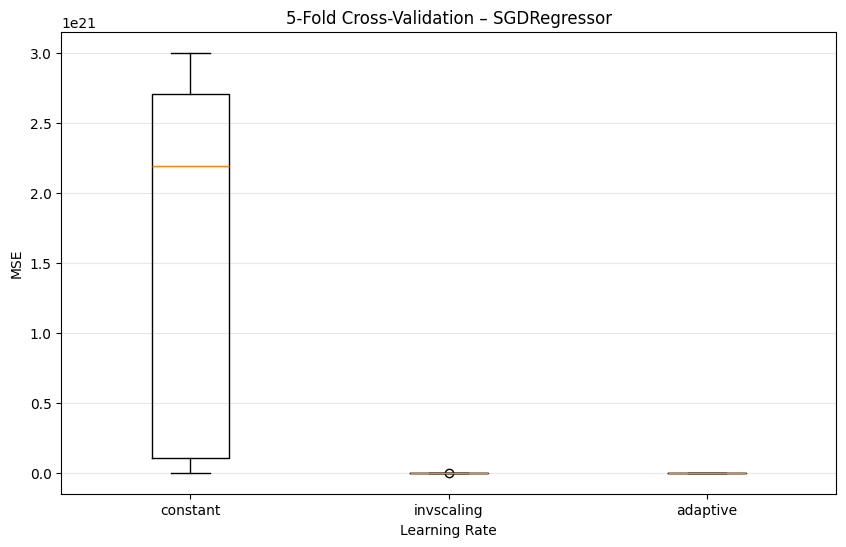

In [ ]:
#zadanie 11
# K-Fold Cross-Validation
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDRegressor
from sklearn.pipeline import Pipeline

housing = fetch_california_housing()

X, y = housing.data, housing.target

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

learning_rates = {
    'constant': 0.01,
    'invscaling': 0.01,
    'adaptive': 0.1
}

results = {}

for strategy, eta in learning_rates.items():

    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('model', SGDRegressor(
            learning_rate=strategy,
            eta0=eta,
            max_iter=1000,
            random_state=42
        ))
    ])

    cv_scores = cross_val_score(
        pipeline,
        X,
        y,
        cv=kf,
        scoring='neg_mean_squared_error'
    )

    mse_scores = -cv_scores

    results[strategy] = mse_scores

    print(f"\nLearning rate: {strategy}")
    print("MSE per fold:", np.round(mse_scores, 4))
    print(f"Mean MSE: {mse_scores.mean():.4f}")
    print(f"Std MSE: {mse_scores.std():.4f}")


summary = pd.DataFrame({
    'Learning Rate': list(results.keys()),
    'Mean MSE': [scores.mean() for scores in results.values()],
    'Std MSE': [scores.std() for scores in results.values()]
})

print("\n=== PODSUMOWANIE ===")
print(summary.to_string(index=False))


plt.figure(figsize=(10, 6))

plt.boxplot(
    [results[strategy] for strategy in learning_rates],
    tick_labels=list(learning_rates.keys())
)

plt.xlabel('Learning Rate')
plt.ylabel('MSE')
plt.title('5-Fold Cross-Validation – SGDRegressor')
plt.grid(axis='y', alpha=0.3)

plt.show()


Liczba próbek | Training MSE | Validation MSE
         1651 |       0.5378 |         8.9593
         3774 |       0.5194 |         1.3900
         5897 |       0.5159 |         1.9807
         8020 |       0.5223 |         0.5830
        10143 |       0.5203 |         0.6072
        12266 |       0.5189 |         0.5290
        14389 |       0.5217 |         0.5281
        16512 |       0.5244 |         0.5270


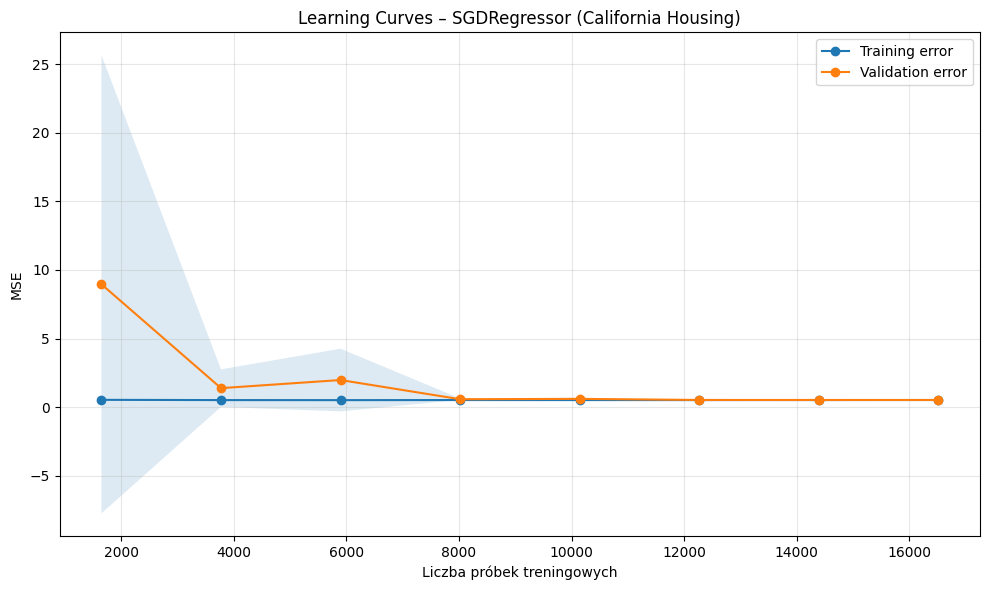

In [ ]:
#zadanie 12
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import learning_curve,KFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDRegressor
from sklearn.pipeline import Pipeline
from sklearn.utils import shuffle

housing = fetch_california_housing()
x,y = housing.data, housing.target
x, y = shuffle(x, y, random_state=42)
cv = KFold(n_splits=5, shuffle=True, random_state=42)

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model',SGDRegressor(
        learning_rate='adaptive',
        eta0=0.0001,
        max_iter=5000,
        tol=1e-4,
        random_state=42
    ))
])

train_sizes, train_scores, validation_scores = learning_curve(
    estimator = pipeline,
    X=x,
    y=y,
    train_sizes=np.linspace(0.1,1.0,8),
    cv=cv,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

train_mse=-train_scores
validation_mse=-validation_scores

train_mean = np.mean(train_mse,axis=1)
train_std = np.std(train_mse,axis=1)

validation_mean=np.mean(validation_mse,axis=1)
validation_std=np.std(validation_mse,axis=1)

print("Liczba próbek | Training MSE | Validation MSE")

for i in range(len(train_sizes)):
    print(
        f"{train_sizes[i]:13d} | "
        f"{train_mean[i]:12.4f} | "
        f"{validation_mean[i]:14.4f}"
    )

plt.figure(figsize=(10,6))

plt.plot(
    train_sizes,
    train_mean,
    marker='o',
    label='Training error'
)

plt.plot(
    train_sizes,
    validation_mean,
    marker='o',
    label='Validation error'
)

plt.fill_between(
    train_sizes,
    validation_mean - validation_std,
    validation_mean + validation_std,
    alpha=0.15
)

plt.xlabel('Liczba próbek treningowych')
plt.ylabel('MSE')
plt.title('Learning Curves – SGDRegressor (California Housing)')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# aktualnie model jest w miarę stabilny. Kluczem było zmniejszenie lr oraz zwiększenie liczby iteracji. Przy innych wartościach model źle się uczy i MSE eksploduje

Dane treningowe: (320, 5)
Dane walidacyjne: (80, 5)
Dane testowe: (100, 5)
Early Stopping! Epoka: 299

PORÓWNANIE MODELI

Early Stopping:
Liczba epok: 299
Najlepszy Validation MSE: 2066.9777
Test MSE: 2655.2143

Bez Early Stopping:
Liczba epok: 1000
Końcowy Validation MSE: 2066.8682
Test MSE: 2655.2304


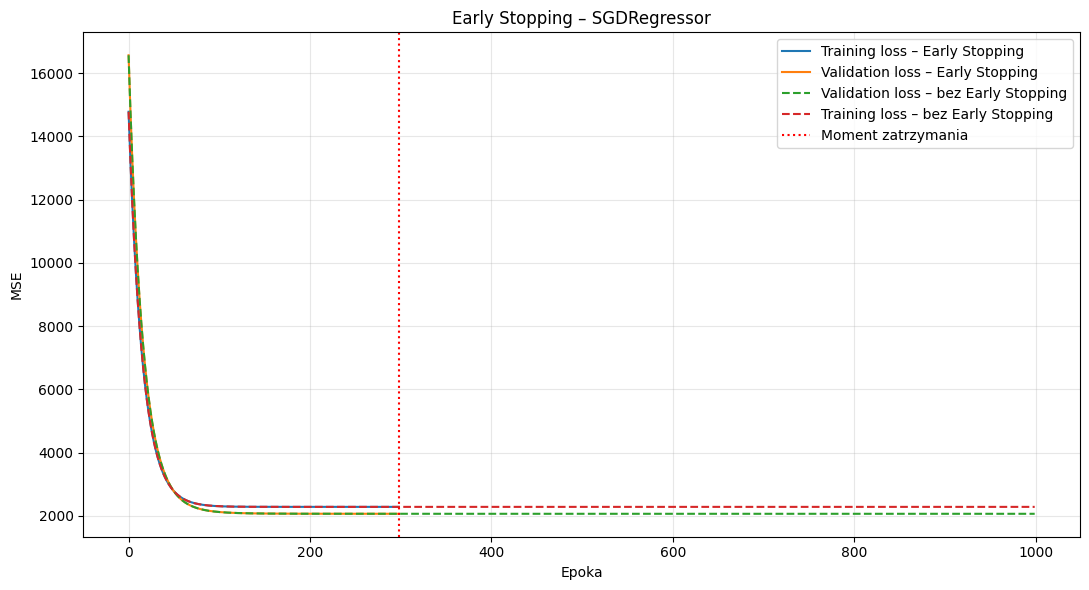

In [25]:
# Zadanie 14  Porównanie Learning Rates
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_squared_error
from sklearn.datasets import make_regression
# Generowanie danych
np.random.seed(42)
X, y = make_regression(n_samples=500, n_features=5, noise=50)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Dane treningowe:", X_train_scaled.shape)
print("Dane walidacyjne:", X_val_scaled.shape)
print("Dane testowe:", X_test_scaled.shape)

def train_model(early_stopping=True):

    max_epochs = 1000
    patience = 10
    min_delta = 1e-6

    # Model SGDRegressor
    model = SGDRegressor(
        learning_rate='constant',
        eta0=0.0001,
        max_iter=1,
        tol=None,
        random_state=42,
        shuffle=False
    )

    best_val_loss = float('inf')
    best_weights = None
    best_intercept = None

    epochs_without_improvement = 0

    train_losses = []
    val_losses = []

    rng = np.random.RandomState(42)

    for epoch in range(max_epochs):

        indices = rng.permutation(len(X_train_scaled))

        X_epoch = X_train_scaled[indices]
        y_epoch = y_train[indices]

        model.partial_fit(X_epoch, y_epoch)

        train_pred = model.predict(X_train_scaled)

        val_pred = model.predict(X_val_scaled)

        train_loss = mean_squared_error(y_train, train_pred)
        val_loss = mean_squared_error(y_val, val_pred)

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        if val_loss < best_val_loss - min_delta:

            best_val_loss = val_loss

            best_weights = model.coef_.copy()
            best_intercept = model.intercept_.copy()

            epochs_without_improvement = 0

        else:
            epochs_without_improvement += 1

        if early_stopping and epochs_without_improvement >= patience:

            print(f"Early Stopping! Epoka: {epoch + 1}")
            break

    if early_stopping:
        model.coef_ = best_weights.copy()
        model.intercept_ = best_intercept.copy()

    return model, train_losses, val_losses


model_es, train_es, val_es = train_model(
    early_stopping=True
)

model_full, train_full, val_full = train_model(
    early_stopping=False
)


pred_es = model_es.predict(X_test_scaled)
pred_full = model_full.predict(X_test_scaled)

test_mse_es = mean_squared_error(y_test, pred_es)
test_mse_full = mean_squared_error(y_test, pred_full)


print("\nPORÓWNANIE MODELI")

print("\nEarly Stopping:")
print("Liczba epok:", len(train_es))
print("Najlepszy Validation MSE:", round(min(val_es), 4))
print("Test MSE:", round(test_mse_es, 4))

print("\nBez Early Stopping:")
print("Liczba epok:", len(train_full))
print("Końcowy Validation MSE:", round(val_full[-1], 4))
print("Test MSE:", round(test_mse_full, 4))


plt.figure(figsize=(11, 6))

plt.plot(
    train_es,
    label='Training loss – Early Stopping'
)

plt.plot(
    val_es,
    label='Validation loss – Early Stopping'
)

plt.plot(
    val_full,
    linestyle='--',
    label='Validation loss – bez Early Stopping'
)

plt.plot(
    train_full,
    linestyle='--',
    label='Training loss – bez Early Stopping'
)

plt.axvline(
    len(train_es) - 1,
    color='red',
    linestyle=':',
    label='Moment zatrzymania'
)

plt.xlabel('Epoka')
plt.ylabel('MSE')
plt.title('Early Stopping – SGDRegressor')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()